# Route and ownership

> Who owns the land a readjustment scheme around the Rotherhithe portal would pool?

Readjustment goes ahead if enough owners, holding enough of the land, vote for it. So we need two things for every
plot near the portal: who owns it, and how much land that is. HM Land Registry has both: title plans (the National
Polygon Service) and the owners of every title held by a company or public body (CCOD and OCOD).


In [ ]:
#| default_exp ownership

In [ ]:
#| export
import re

import geopandas as gpd
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import Point, box
from shapely.ops import split

from tunnel.config import BNG, SOUTH_PORTAL, WGS84, catchment, to_bng
from tunnel.data import company_owners, open_space, tenures, thames, title_plans

In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import test_close, test_eq
from matplotlib.lines import Line2D
from shapely.geometry import LineString

from tunnel.config import (
    CATCHMENT_M,
    CHART_DATUM_ODN,
    COLOURS,
    DERIVED,
    FIGURES,
    HEADROOM_M,
    NORTH_HEAD,
    NORTH_RIVER,
    QUAY_ODN,
    RIVERBED_CD,
    ROOF_M,
    SOUTH_HEAD,
    SOUTH_RIVER,
    entrances,
    ramp_lengths,
    ramps,
    river_crossing,
    to_lonlat,
    use_style,
    walkway_profile,
)  # fmt: skip
from tunnel.data import buildings as buildings_in
from tunnel.data import jubilee_tunnels

use_style()

## The readjustment area

The area is the circle around the Rotherhithe portal at the head of Nelson Dock, but only the Rotherhithe bank: the Isle of Dogs is a different borough
and a different scheme. Splitting the circle along the river's centre line gives two pieces, and we keep the one
with the portal in it.


In [ ]:
#| export
def rotherhithe_side(area):
    "The part of `area` (BNG) on the south bank, i.e. the side of the Thames with the south portal."
    river = shapely.line_merge(thames().union_all())
    return next(p for p in split(area, river).geoms if p.contains(Point(to_bng(SOUTH_PORTAL))))

In [ ]:
side = rotherhithe_side(catchment())
test_eq(side.area < catchment().area, True)
f"{catchment().area / 1e4:.0f} ha in the circle, {side.area / 1e4:.0f} ha on the Rotherhithe side"

'176 ha in the circle, 101 ha on the Rotherhithe side'

That still includes half the river, the docks and the parks. Nobody is going to build on those.


In [ ]:
#| export
def constraints(area):
    "OSM parks, water, schools and places of worship touching `area` (BNG)."
    c = open_space(tuple(gpd.GeoSeries([area], crs=BNG).to_crs(WGS84).total_bounds))
    return c[c.intersects(area)]


def catchment_land(exclude=("open_space", "water")):
    "The Rotherhithe side of the catchment, minus the constraint classes in `exclude`."
    side = rotherhithe_side(catchment())
    c = constraints(side)
    return side.difference(c[c["class"].isin(exclude)].union_all())

In [ ]:
land = catchment_land()
f"{land.area / 1e4:.1f} ha excluding parks and water"

'57.7 ha excluding parks and water'

## Who's who

We sort owners into four groups. Southwark Council is the largest, and would run the scheme. Housing associations
register in several legal forms, so we go by their category in CCOD as well as their name. Anything not in CCOD or
OCOD belongs to private individuals.


In [ ]:
#| export
GROUPS = {
    "southwark": "Southwark Council",
    "housing": "Housing associations",
    "other": "Other companies and bodies",
    "private": "Private individuals",
}
HOUSING_CATEGORIES = ("Housing Association", "Community Benefit", "Registered Society", "Industrial and Provident")


def classify(owner, category):
    "The `GROUPS` key for a title's owner, from CCOD's name and proprietorship category."
    if pd.isna(category):
        return "private"
    if "SOUTHWARK" in str(owner) and category == "Local Authority":
        return "southwark"
    if any(k in category for k in HOUSING_CATEGORIES) or "HOUSING" in str(owner):
        return "housing"
    return "other"

In [ ]:
SOUTHWARK = "THE MAYOR AND BURGESSES OF THE LONDON BOROUGH OF SOUTHWARK"
test_eq(classify(SOUTHWARK, "Local Authority"), "southwark")
test_eq(classify("SOUTHERN HOUSING", "Registered Society (Corporate Body)"), "housing")
test_eq(classify("HEXAGON HOUSING ASSOCIATION LIMITED", "Limited Company or Public Limited Company"), "housing")
test_eq(classify("SOUTHWARK DIOCESAN BOARD OF EDUCATION", "Corporate Body"), "other")
test_eq(classify(None, None), "private")

Registered names are long and shouty. Most shorten by rule; a handful need an alias.


In [ ]:
#| export
ALIASES = {
    r"BOROUGH OF SOUTHWARK": "Southwark Council",
    r"^AVIVA INVESTORS": "Aviva Investors",
    r"^FAIRHOLD": "Fairhold Holdings",
    r"SOUTHWARK DIOCESAN BOARD OF EDUCATION": "Southwark Diocesan Board of Education",
    r"ROMAN CATHOLIC ARCHDIOCESE OF SOUTHWARK": "RC Archdiocese of Southwark",
    r"ROTHERHITHE HOLY TRINITY": "Holy Trinity, Rotherhithe",
    r"^TRANSPORT FOR LONDON": "Transport for London",
    r"SURREY DOCKS FARM": "Surrey Docks Farm",
    r"^265 ROTHERHITHE STREET": "265 Rotherhithe Street S.a.r.l.",
    r"^ACORN YARD": "Acorn Yard Management Co.",
}


def short_name(owner):
    "A readable name for a registered proprietor."
    if pd.isna(owner):
        return "Private individual(s)"
    for pattern, name in ALIASES.items():
        if re.search(pattern, owner):
            return name
    name = re.sub(r"\s+(LIMITED|LTD\.?|PLC|LLP)$", "", owner.strip())
    name = re.sub(r"\s*\((SURREY DOCKS|\d{4})\)", "", name)
    return " ".join(w.capitalize() if w.isalpha() else w.title() for w in name.split())

In [ ]:
test_eq(short_name(SOUTHWARK), "Southwark Council")
test_eq(short_name("HEXAGON HOUSING ASSOCIATION LIMITED"), "Hexagon Housing Association")
test_eq(short_name("HOLDING & MANAGEMENT (SOLITAIRE) LIMITED"), "Holding & Management (Solitaire)")
test_eq(short_name("VEGA PROPERTIES NO 3 LIMITED"), "Vega Properties No 3")
test_eq(short_name(None), "Private individual(s)")

## Overlapping plots

Title plans overlap. A block of flats has a freehold title for the whole site and a leasehold title for every flat,
all drawn on the same footprint. Counting them all would count the land many times over.

Here's a toy site: a 10 m square freehold, a 2 m square freehold carved out of one corner (a substation, say), a
leasehold flat inside the big square, and a neighbour that only just overlaps it.


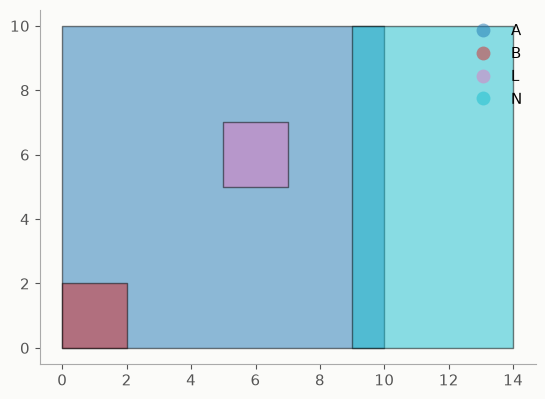

In [ ]:
toy = gpd.GeoDataFrame(
    {"title_no": ["A", "B", "L", "N"], "tenure": ["Freehold", "Freehold", "Leasehold", "Freehold"]},
    geometry=[box(0, 0, 10, 10), box(0, 0, 2, 2), box(5, 5, 7, 7), box(9, 0, 14, 10)],
    crs=BNG,
).assign(area_m2=lambda d: d.area)
toy.plot(column="title_no", alpha=0.5, edgecolor="k", legend=True);

For drawing maps we drop plots that sit almost entirely inside a bigger one, since they'd be hidden anyway.


In [ ]:
#| export
def top_level(g):
    "False for plots at least 80% covered by a single larger plot (sub-titles, leases)."
    area = g.area.to_numpy()
    left, right = g.sindex.query(g.geometry, predicate="intersects")
    bigger = area[right] > area[left] * 1.05
    left, right = left[bigger], right[bigger]
    cover = shapely.area(shapely.intersection(g.geometry.values[left], g.geometry.values[right])) / area[left]
    covered = np.zeros(len(g), dtype=bool)
    covered[left[cover >= 0.8]] = True
    return ~covered

In [ ]:
test_eq(list(top_level(toy)), [True, False, False, True])

For counting land we want each square metre once, held by the freeholder who would vote on it. So we ignore
leaseholds and, where freeholds overlap, give the land to the smaller plot: a small freehold inside a big one is
usually land sold off from it.


In [ ]:
#| export
def freehold_land(g, land):
    "Freehold plots clipped to `land`, with `net_m2`: what each holds once overlaps go to the smaller plot."
    fh = g[g.tenure == "Freehold"].copy()
    fh["geometry"] = fh.geometry.intersection(land)
    fh = fh[~fh.is_empty].sort_values("area_m2")
    taken, net = shapely.Polygon(), []
    for geom in fh.geometry:
        net.append(geom.difference(taken).area)
        taken = taken.union(geom)
    return fh.assign(net_m2=net)

In [ ]:
fh_toy = freehold_land(toy, box(0, 0, 12, 10)).set_index("title_no").net_m2
test_eq(dict(fh_toy), {"B": 4, "N": 30, "A": 100 - 4 - 10})

B keeps its 4 m². N, smaller than A, keeps all 30 m² of itself inside the area, including the 1 m strip it shares
with A. A gets the rest.
The leasehold plays no part. The totals add up to the land covered, with nothing counted twice:


In [ ]:
test_close(fh_toy.sum(), box(0, 0, 12, 10).area)

Finally, add up each owner's land. Private individuals are many small owners, so they go in as one row.


In [ ]:
#| export
def owner_shares(fh):
    "Land held by each company or public owner, largest first, then private individuals as one row."
    agg = {"net_m2": ("net_m2", "sum"), "titles": ("title_no", "nunique")}
    named = fh[fh.group != "private"].groupby(["name", "group"], as_index=False).agg(**agg)
    private = (
        fh[fh.group == "private"]
        .assign(name="Private individuals")
        .groupby(["name", "group"], as_index=False)
        .agg(**agg)
    )
    rows = pd.concat([named.sort_values("net_m2", ascending=False), private], ignore_index=True)
    return rows.assign(share=rows.net_m2 / rows.net_m2.sum())

In [ ]:
toy_fh = pd.DataFrame({
    "title_no": list("abcde"), "name": ["Council", "Council", "HA", "Private individual(s)", "Private individual(s)"],
    "group": ["southwark", "southwark", "housing", "private", "private"], "net_m2": [50, 10, 30, 6, 4],
})  # fmt: skip
toy_shares = owner_shares(toy_fh)
test_eq(list(toy_shares.name), ["Council", "HA", "Private individuals"])
test_eq(list(toy_shares.share), [0.6, 0.3, 0.1])
test_eq(list(toy_shares.titles), [2, 1, 2])

## The real thing

`plots` puts it together for every title plan touching an area: tenure, owner, group and a short name.


In [ ]:
#| export
def plots(area):
    "Title plans touching `area` (BNG), with tenure, owner, owner group and a short owner name."
    g = title_plans(area)
    titles = set(g.title_no)
    g = g.merge(company_owners(titles), on="title_no", how="left")
    g["tenure"] = g.tenure.fillna(g.title_no.map(tenures(titles)))
    g["group"] = [classify(o, c) for o, c in zip(g.owner, g.owner_category)]
    g["name"] = g.owner.map(short_name)
    g["area_m2"] = g.area
    return g.assign(top_level=top_level(g))

In [ ]:
g = plots(side)
fh = freehold_land(g, land)
shares = owner_shares(fh)
g.to_file(DERIVED / "catchment_plots.gpkg", driver="GPKG")  # for the crossing map, which then needs no NPS files
print(f"{g.title_no.nunique():,} titles; {len(fh):,} freehold plots cover {fh.net_m2.sum() / 1e4:.1f} ha")
shares.head(12).assign(ha=lambda d: (d.net_m2 / 1e4).round(2), pct=lambda d: (100 * d.share).round(1))[
    ["name", "group", "titles", "ha", "pct"]
]

3,235 titles; 1,301 freehold plots cover 55.4 ha


,name,group,titles,ha,pct
0,Southwark Council,southwark,33,21.68,39.1
1,Southern Housing,housing,14,4.21,7.6
2,Southwark Diocesan Board of Education,other,3,2.24,4.0
3,Holding & Management (Solitaire),other,6,2.18,3.9
4,Aviva Investors,other,2,1.79,3.2
5,Sanctuary Housing Association,housing,3,1.42,2.6
6,265 Rotherhithe Street S.a.r.l.,other,1,1.10,2.0
7,Acorn Yard Management Co.,other,1,0.92,1.7
8,Pageant Steps,other,1,0.72,1.3
9,Fairhold Holdings,other,1,0.70,1.3


## Could a supermajority be found?


In [ ]:
named = shares[shares.group != "private"].assign(cumulative=lambda d: d.share.cumsum())
n_two_thirds = int((named.cumulative < 2 / 3).sum()) + 1
council_and_ha = named[named.group.isin(["southwark", "housing"])]
private = g[g.group == "private"]
print(f"Southwark Council holds {named.share[named.group == 'southwark'].sum():.0%}")
print(f"with {(council_and_ha.group == 'housing').sum()} housing associations, {council_and_ha.share.sum():.0%}")
print(f"{n_two_thirds} owners between them hold two-thirds")
print(f"Private individuals hold {shares.share.iloc[-1]:.0%} on {shares.titles.iloc[-1]:,} freehold titles")
print(
    f"Private titles of any tenure: {private.title_no.nunique():,}, of which {(private.drop_duplicates('title_no').tenure == 'Leasehold').sum():,} leasehold"
)

Southwark Council holds 39%
with 7 housing associations, 52%
10 owners between them hold two-thirds
Private individuals hold 17% on 767 freehold titles
Private titles of any tenure: 2,807, of which 2,030 leasehold


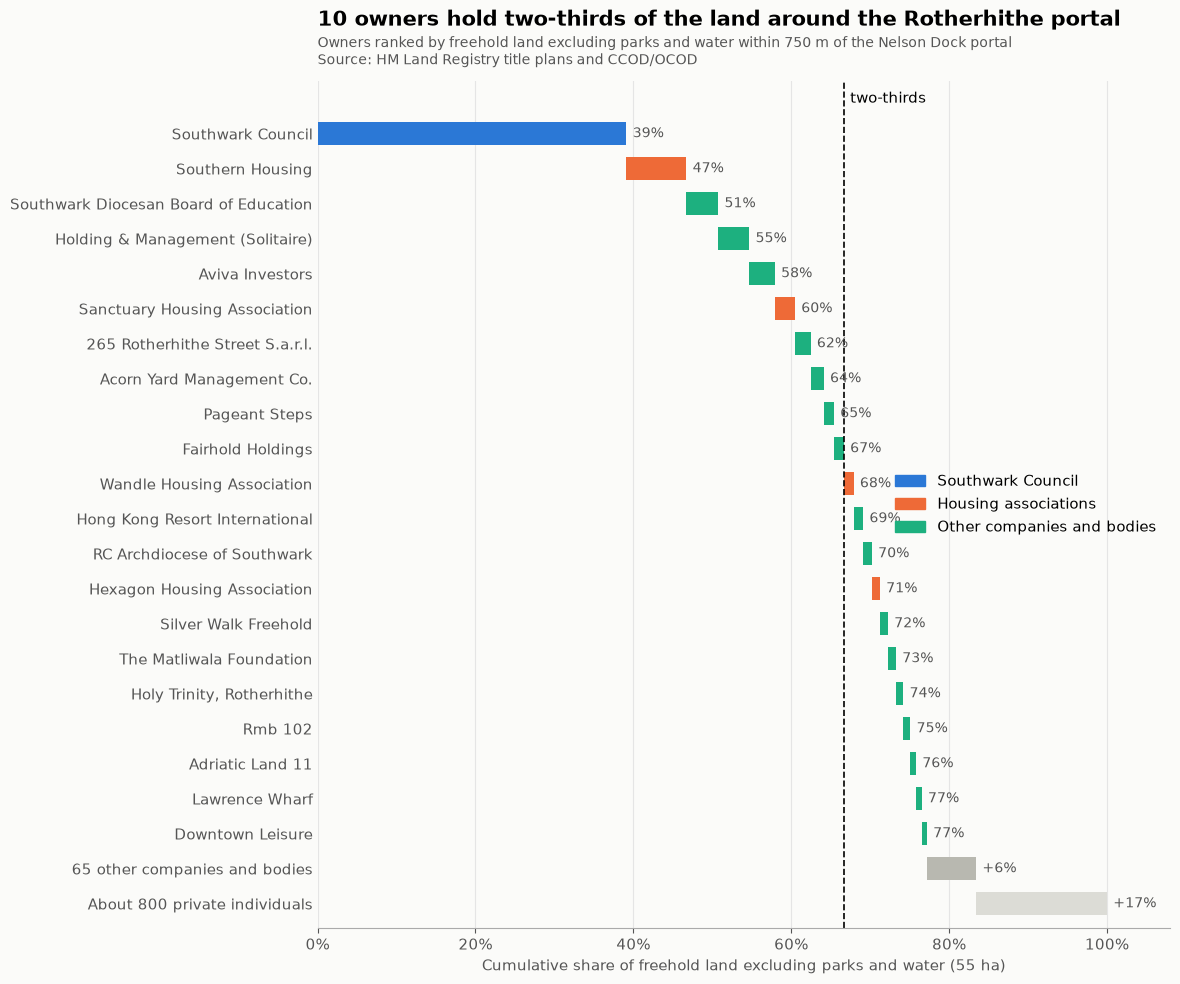

In [ ]:
TOP = 21
rest = named.iloc[TOP:]
bars = pd.concat([
    named.head(TOP)[["name", "group", "share"]],
    pd.DataFrame([
        {"name": f"{len(rest)} other companies and bodies", "group": "rest", "share": rest.share.sum()},
        {"name": f"About {round(shares.titles.iloc[-1], -2):,.0f} private individuals", "group": "private", "share": shares.share.iloc[-1]},
    ]),
], ignore_index=True).assign(start=lambda d: d.share.cumsum() - d.share)  # fmt: skip

fig, ax = plt.subplots(figsize=(11, 11))
y = np.arange(len(bars))[::-1]
ax.barh(y, bars.share, left=bars.start, color=bars.group.map(COLOURS), height=0.65)
for yi, r in zip(y, bars.itertuples()):
    label = f"+{r.share:.0%}" if r.group in ("rest", "private") else f"{r.start + r.share:.0%}"
    ax.text(r.start + r.share + 0.008, yi, label, va="center", fontsize=10, color=COLOURS["text"])
ax.set_yticks(y, bars.name)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.axvline(2 / 3, color="black", ls="--", lw=1.2)
ax.text(2 / 3 + 0.008, y[0] + 1, "two-thirds", va="center")
ax.set(xlim=(0, 1.08), ylim=(-0.7, len(bars) + 0.5))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
ax.set_xlabel(f"Cumulative share of freehold land excluding parks and water ({shares.net_m2.sum() / 1e4:.0f} ha)")
keys = ["southwark", "housing", "other"]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLOURS[k]) for k in keys], [GROUPS[k] for k in keys], loc="center right")
ax.set_title(f"{n_two_thirds} owners hold two-thirds of the land around the Rotherhithe portal", pad=40)
ax.text(0, 1.02, f"Owners ranked by freehold land excluding parks and water within {CATCHMENT_M} m of the Nelson Dock portal\n"
        "Source: HM Land Registry title plans and CCOD/OCOD", transform=ax.transAxes, color=COLOURS["text"], fontsize=10)  # fmt: skip
fig.savefig(FIGURES / "land_supermajority.png")

## The route

### In section

The config notebook works out how deep the tube must go under the riverbed, and how much of the climb back up is left
for ramps on land. Here it is end to end, from the Rotherhithe entrance to the Canary Wharf one.

'entrance to entrance 944 m; walkway lowest at -14.9 m ODN'

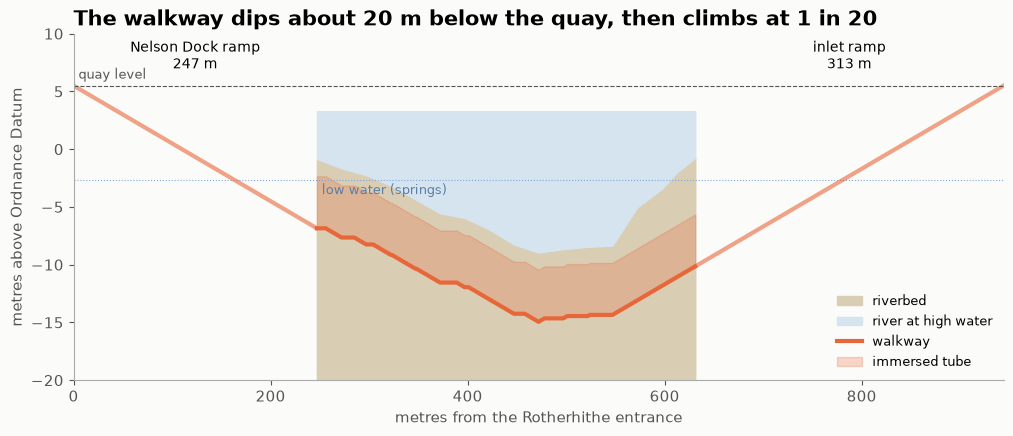

In [ ]:
xs, w = walkway_profile()
south_ramp, north_ramp = ramp_lengths()
bed = np.interp(xs, *zip(*RIVERBED_CD)) + CHART_DATUM_ODN
d = xs + south_ramp  # distance from the south entrance
MHW, MLWS = 3.28, -2.69  # PLA chart 319, West India Pier (m ODN)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(d, bed, -25, color="#d9cdb4", label="riverbed")
ax.fill_between(d, bed, MHW, color=COLOURS["water"], label="river at high water")
ax.axhline(MLWS, color="#7fa7d9", lw=0.8, ls=":")
ax.text(d[0] + 5, MLWS - 1.2, "low water (springs)", color="#5a7fa8", fontsize=9)
ramp_s = np.array([0, south_ramp]), np.array([QUAY_ODN, w[0]])
ramp_n = np.array([d[-1], d[-1] + north_ramp]), np.array([w[-1], QUAY_ODN])
for xx, yy in (ramp_s, ramp_n):
    ax.plot(xx, yy, color=COLOURS["tunnel"], lw=3, alpha=0.6)
ax.plot(d, w, color=COLOURS["tunnel"], lw=3, label="walkway")
ax.fill_between(d, w, w + HEADROOM_M + ROOF_M, color=COLOURS["tunnel"], alpha=0.25, label="immersed tube")
ax.axhline(QUAY_ODN, color="#555", lw=0.8, ls="--")
ax.text(5, QUAY_ODN + 0.6, "quay level", color="#555", fontsize=9)
for x, label in (
    (south_ramp / 2, f"Nelson Dock ramp\n{south_ramp:.0f} m"),
    (d[-1] + north_ramp / 2, f"inlet ramp\n{north_ramp:.0f} m"),
):
    ax.text(x, QUAY_ODN + 1.5, label, ha="center", fontsize=10)
ax.set(
    xlim=(0, d[-1] + north_ramp),
    ylim=(-20, 10),
    xlabel="metres from the Rotherhithe entrance",
    ylabel="metres above Ordnance Datum",
)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("The walkway dips about 20 m below the quay, then climbs at 1 in 20")
fig.savefig(FIGURES / "tunnel_profile.png")
f"entrance to entrance {d[-1] + north_ramp:.0f} m; walkway lowest at {w.min():.1f} m ODN"

The riverbed's foreshore is shallow near each bank, so the walkway can only climb part of the way back up under the
river. At the river walls it is still 12 to 16 m below the quay, which is where the ramps on land begin.

### In plan

The ramps don't fit in a straight line: run straight inland from each dock, they would end well beyond the docks,
among the buildings behind. So in our design they fold back and forth inside each dock (see the config notebook),
with the entrance where the last fold ends.

In [ ]:
def straight_ramp(mouth, head, length):
    "A ramp of `length` running straight inland from `mouth` past `head`, in BNG."
    mouth, head = np.array(mouth, float), np.array(head, float)
    along = (head - mouth) / np.linalg.norm(head - mouth)
    return LineString([mouth, mouth + along * length])


folded = ramps()
straight = straight_ramp(SOUTH_RIVER, SOUTH_HEAD, south_ramp), straight_ramp(NORTH_RIVER, NORTH_HEAD, north_ramp)
river = river_crossing()
x0, y0, x1, y1 = shapely.union_all([river, *straight]).buffer(120).bounds
view = box(x0, y0, x1, y1)
lon0, lat0 = to_lonlat((x0, y0))
lon1, lat1 = to_lonlat((x1, y1))
buildings = buildings_in((lon0, lat0, lon1, lat1))
cons = constraints(view.buffer(300))
jubilee = jubilee_tunnels().clip(view)
crosses = river.intersects(jubilee.union_all())
{
    "under the river (m)": round(river.length),
    "Jubilee line": "passes over it" if crosses else "clear of it",
    "straight ramps end beyond the dock heads by (m)": [
        round(Point(s.coords[-1]).distance(Point(h))) for s, h in zip(straight, (SOUTH_HEAD, NORTH_HEAD))
    ],
    "straight ramps cross buildings": [int(buildings.intersects(s).sum()) for s in straight],
}

{'under the river (m)': 384,
 'Jubilee line': 'passes over it',
 'straight ramps end beyond the dock heads by (m)': [152, 237],
 'straight ramps cross buildings': [4, 1]}

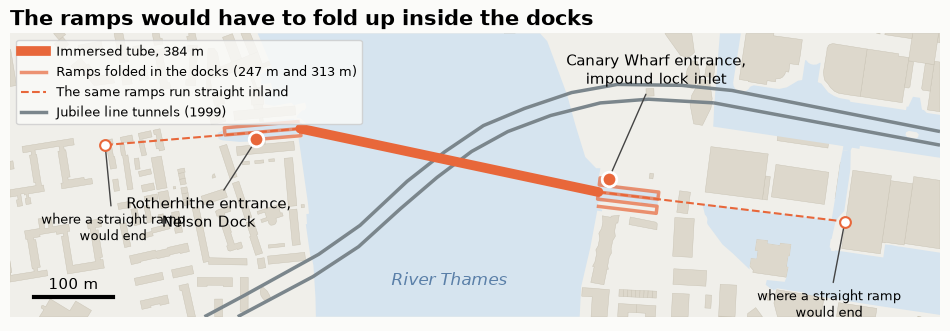

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
gpd.GeoSeries([view], crs=BNG).plot(ax=ax, color=COLOURS["land"])
buildings.clip(view).plot(ax=ax, color="#ddd8cc", edgecolor="#c8c2b3", lw=0.3)
cons[cons["class"] == "water"].clip(view).plot(ax=ax, color=COLOURS["water"])
jubilee.plot(ax=ax, color=COLOURS["jubilee"], lw=2.5)
gpd.GeoSeries(list(straight), crs=BNG).plot(ax=ax, color=COLOURS["tunnel"], lw=1.5, ls="--")
gpd.GeoSeries(list(folded), crs=BNG).plot(ax=ax, color=COLOURS["tunnel"], lw=2.5, alpha=0.7)
gpd.GeoSeries([river], crs=BNG).plot(ax=ax, color=COLOURS["tunnel"], lw=7, capstyle="round")
ex, ey = zip(*entrances())
ax.scatter(ex, ey, s=110, color=COLOURS["tunnel"], edgecolor="white", lw=2, zorder=5)
sx, sy = straight[0].coords[-1]
nx, ny = straight[1].coords[-1]
ax.scatter([sx, nx], [sy, ny], s=60, facecolor="white", edgecolor=COLOURS["tunnel"], lw=1.5, zorder=5)
arrow = {"arrowstyle": "-", "color": "#444", "lw": 1}
ax.annotate(
    "Rotherhithe entrance,\nNelson Dock",
    (ex[0], ey[0]),
    xytext=(ex[0] - 60, ey[0] - 110),
    ha="center",
    arrowprops=arrow,
)
ax.annotate(
    "Canary Wharf entrance,\nimpound lock inlet",
    (ex[1], ey[1]),
    xytext=(ex[1] + 60, ey[1] + 120),
    ha="center",
    arrowprops=arrow,
)
ax.annotate(
    "where a straight ramp\nwould end", (sx, sy), xytext=(sx + 10, sy - 120), ha="center", arrowprops=arrow, fontsize=9
)
ax.annotate(
    "where a straight ramp\nwould end", (nx, ny), xytext=(nx - 20, ny - 120), ha="center", arrowprops=arrow, fontsize=9
)
ax.text(
    (SOUTH_RIVER[0] + NORTH_RIVER[0]) / 2,
    y0 + 40,
    "River Thames",
    fontsize=12,
    style="italic",
    color="#5a7fa8",
    ha="center",
)
ax.plot([x0 + 30, x0 + 130], [y0 + 25, y0 + 25], color="black", lw=3)
ax.text(x0 + 80, y0 + 35, "100 m", ha="center")
ax.legend(handles=[
    Line2D([0], [0], color=COLOURS["tunnel"], lw=7, label=f"Immersed tube, {river.length:.0f} m"),
    Line2D([0], [0], color=COLOURS["tunnel"], lw=2.5, alpha=0.7, label=f"Ramps folded in the docks ({south_ramp:.0f} m and {north_ramp:.0f} m)"),
    Line2D([0], [0], color=COLOURS["tunnel"], lw=1.5, ls="--", label="The same ramps run straight inland"),
    Line2D([0], [0], color=COLOURS["jubilee"], lw=2.5, label="Jubilee line tunnels (1999)"),
], loc="upper left", frameon=True, fontsize=9, bbox_to_anchor=(0, 1.0))  # fmt: skip
ax.set(xlim=(x0, x1), ylim=(y0, y1))
ax.set_axis_off()
ax.set_title("The ramps would have to fold up inside the docks")
fig.savefig(FIGURES / "route_map.png")